# Analyse Exploratoire

**Contexte** : prédire la **consommation totale d'énergie** (`SiteEnergyUse(kBtu)`) et les **émissions de CO2** (`TotalGHGEmissions`) des bâtiments **non résidentiels** de Seattle à partir de leurs caractéristiques structurelles, afin d'éviter des relevés coûteux. Source : *2016 Building Energy Benchmarking* (Ville de Seattle).

Les deux cibles sont modélisées avec **exactement la même démarche** (mêmes bâtiments, mêmes features, même split train/test, mêmes métriques).

### Import des modules

In [1]:
#!pip install xgboost

In [2]:
import numpy as np  # numpy : calcul numérique (logarithmes, racines carrées, tableaux)
import pandas as pd  # pandas : manipulation de tableaux de données (DataFrame)
import matplotlib.pyplot as plt  # matplotlib : tracer des graphiques
import seaborn as sns  # seaborn : graphiques statistiques plus jolis, construits sur matplotlib
from xgboost import XGBRegressor

### Déclaration fonction

In [3]:
def plot_valeurs_par_colonne(d, titre):  # définit une fonction réutilisable (brut puis après nettoyage) pour tracer les valeurs par colonne
    """Barres empilées : valeurs renseignées (bleu) et valeurs vides (rouge) pour chaque colonne."""
    n = len(d)  # nombre total de lignes du tableau
    renseignees = d.notna().sum()  # pour chaque colonne : combien de valeurs ne sont pas vides
    vides = n - renseignees  # pour chaque colonne : combien de valeurs sont vides
    ordre = vides.sort_values(ascending=True).index  # trie les colonnes par nombre de vides (les plus vides finiront en haut du graphique)
    fig, ax = plt.subplots(figsize=(11, 0.3 * len(d.columns) + 1.5))  # crée la figure, sa hauteur s'adapte au nombre de colonnes
    ax.barh(ordre, renseignees[ordre], color="steelblue", label="Valeurs renseignées")  # barres bleues horizontales : valeurs présentes
    ax.barh(ordre, vides[ordre], left=renseignees[ordre], color="indianred", label="Valeurs vides")  # barres rouges collées à la suite des bleues : valeurs vides
    for i, c in enumerate(ordre):  # parcourt chaque colonne avec sa position verticale
        if vides[c] > 0:  # on n'écrit un texte que si la colonne contient des vides
            ax.text(n * 1.01, i, f"{vides[c]} vides ({vides[c] / n:.0%})", va="center", fontsize=8)  # écrit le nombre et le % de vides à droite de la barre
    ax.set_xlim(0, n * 1.25)  # laisse de la place à droite pour ces textes
    ax.set_xlabel("Nombre de bâtiments")  # légende de l'axe horizontal
    ax.set_title(f"{titre} — {n} lignes")  # titre du graphique avec le nombre de lignes
    ax.legend(loc="lower right")  # affiche la légende bleu/rouge en bas à droite
    plt.tight_layout(); plt.show()  # ajuste les marges puis affiche le graphique

In [4]:
# Fonction pour garder une trace du nombre de lignes avant/après chaque filtrage
log_filtrage = []  # liste vide qui va mémoriser chaque étape de filtrage

def suivre(df_avant, df_apres, etape):  # fonction qui enregistre et affiche l'effet d'un filtre
    log_filtrage.append({"étape": etape, "avant": len(df_avant), "après": len(df_apres),  # ajoute à la liste : nom de l'étape, lignes avant, lignes après
                         "supprimées": len(df_avant) - len(df_apres)})  # et nombre de lignes supprimées
    print(f"{etape:<65} {len(df_avant):>5} -> {len(df_apres):>5}  (-{len(df_avant) - len(df_apres)})")  # affiche une ligne de suivi lisible

### Analyse Exploratoire

In [5]:
building_consumption = pd.read_csv("2016_Building_Energy_Benchmarking.csv")  # charge le fichier des relevés 2016 dans un DataFrame
print("Dimensions initiales :", building_consumption.shape)  # affiche (nb de lignes, nb de colonnes) pour garder une trace de départ

Dimensions initiales : (3376, 46)


In [6]:
# On regarde comment un batiment est défini dans ce jeu de données
building_consumption.head()  # affiche les 5 premières lignes : une ligne = un bâtiment

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,...,Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,...,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,...,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,...,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,...,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,...,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88


In [7]:
# On regarde le nombre de valeurs manquantes par colonne ainsi que leur type
building_consumption.info()  # liste chaque colonne avec son type et son nombre de valeurs non vides

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 46 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   OSEBuildingID                    3376 non-null   int64  
 1   DataYear                         3376 non-null   int64  
 2   BuildingType                     3376 non-null   object 
 3   PrimaryPropertyType              3376 non-null   object 
 4   PropertyName                     3376 non-null   object 
 5   Address                          3376 non-null   object 
 6   City                             3376 non-null   object 
 7   State                            3376 non-null   object 
 8   ZipCode                          3360 non-null   float64
 9   TaxParcelIdentificationNumber    3376 non-null   object 
 10  CouncilDistrictCode              3376 non-null   int64  
 11  Neighborhood                     3376 non-null   object 
 12  Latitude            

#### TERMINER L'ANALYSE EXPLORATOIRE

#### 0. Nombre de valeurs par colonne et valeurs vides (jeu de données brut)

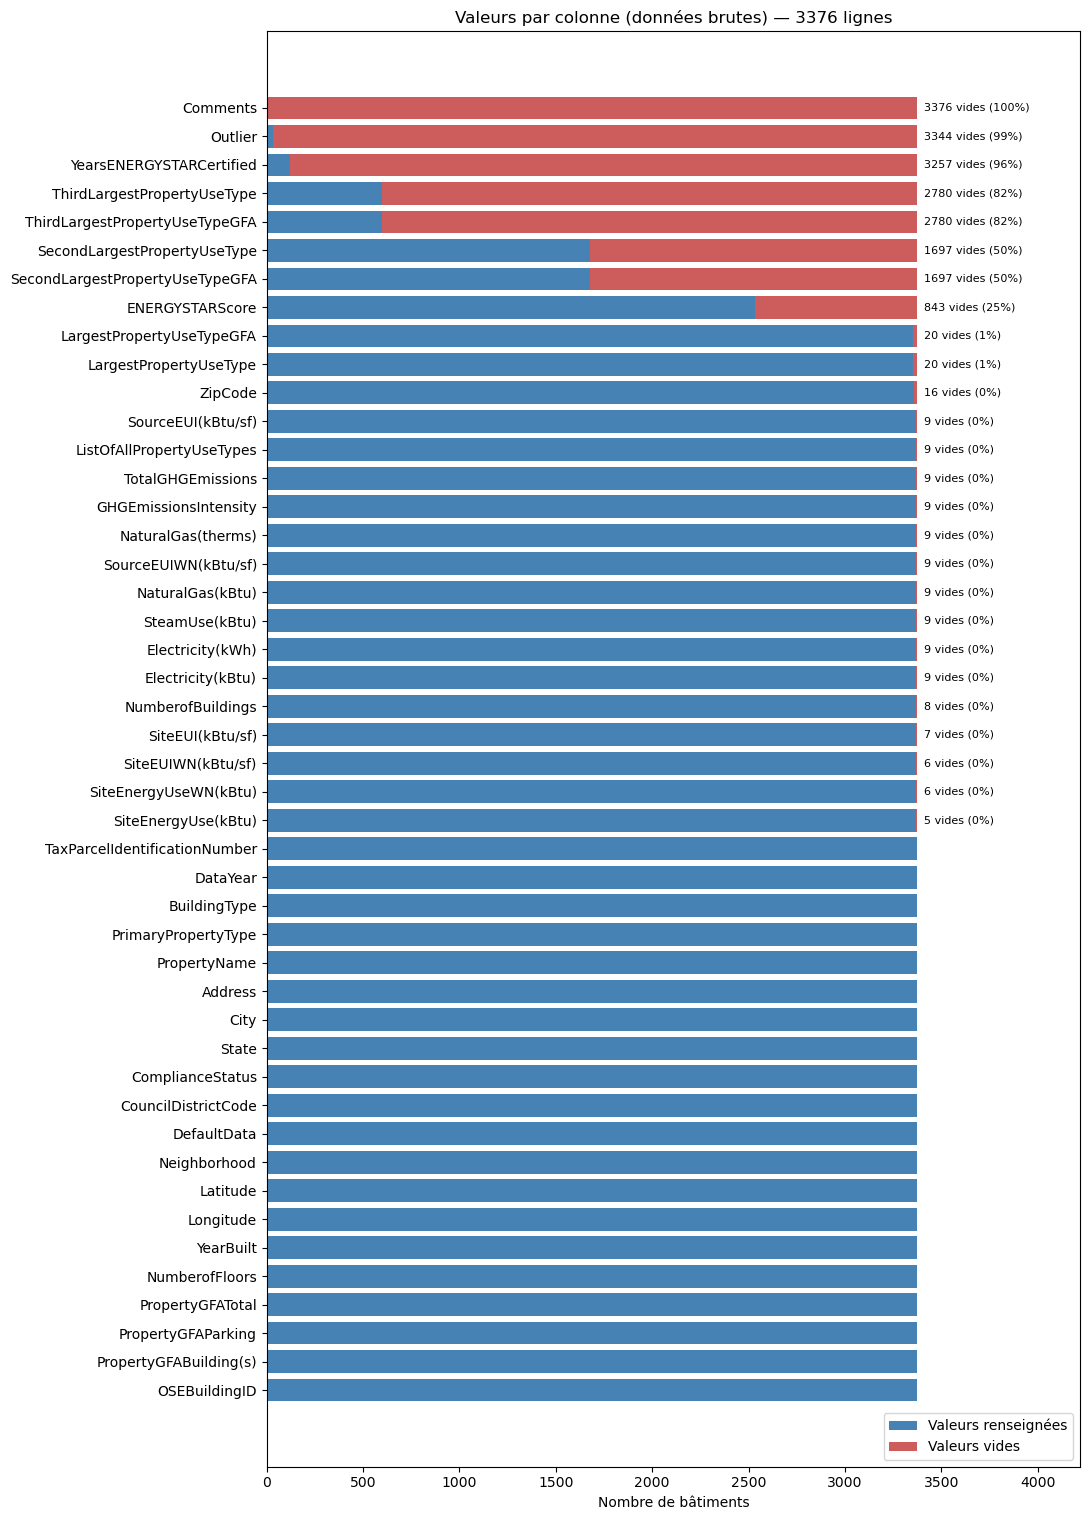

In [8]:
plot_valeurs_par_colonne(building_consumption, "Valeurs par colonne (données brutes)")  # appelle la fonction sur les données brutes

#### 1. Périmètre : ne garder que les bâtiments non destinés à l'habitation

In [9]:
print(building_consumption["BuildingType"].value_counts())  # compte les bâtiments par type (pour repérer les logements Multifamily)
print()
print(building_consumption["PrimaryPropertyType"].value_counts())  # compte les bâtiments par type de propriété principal

BuildingType
NonResidential          1460
Multifamily LR (1-4)    1018
Multifamily MR (5-9)     580
Multifamily HR (10+)     110
SPS-District K-12         98
Nonresidential COS        85
Campus                    24
Nonresidential WA          1
Name: count, dtype: int64

PrimaryPropertyType
Low-Rise Multifamily           987
Mid-Rise Multifamily           564
Small- and Mid-Sized Office    293
Other                          256
Warehouse                      187
Large Office                   173
K-12 School                    139
Mixed Use Property             133
High-Rise Multifamily          105
Retail Store                    91
Hotel                           77
Worship Facility                71
Distribution Center             53
Senior Care Community           45
Supermarket / Grocery Store     40
Medical Office                  39
Self-Storage Facility           28
University                      25
Residence Hall                  23
Refrigerated Warehouse          12
Restaura

`BuildingType` contient trois catégories de logements collectifs (`Multifamily LR / MR / HR`) qui sont **hors périmètre** de l'énoncé. Les types `NonResidential`, `Nonresidential COS`, `Nonresidential WA`, `SPS-District K-12` (écoles) et `Campus` sont conservés.

In [10]:
# 1) Suppression des logements
df = building_consumption.copy()  # copie de travail : on garde les données brutes intactes
filtre_logement = ~df["BuildingType"].str.contains("Multifamily", case=False, na=False)  # True pour les bâtiments dont le type ne contient PAS "Multifamily" (~ = négation)
suivre(df, df[filtre_logement], "Retrait des bâtiments Multifamily (habitation)")  # enregistre l'effet de ce filtre
df = df[filtre_logement].copy()  # applique le filtre : on ne garde que les lignes où le masque est vrai

Retrait des bâtiments Multifamily (habitation)                     3376 ->  1668  (-1708)


#### 2. Repérer les bâtiments aberrants ou peu pertinents
Colonnes utiles : `Outlier` (signalement par la ville), `ComplianceStatus`, `DefaultData` (valeurs par défaut non réelles) et le sens des valeurs (surfaces ou consommations nulles).

In [11]:
print(df["ComplianceStatus"].value_counts(), "\n")  # statuts de conformité du relevé (seuls les "Compliant" sont fiables)
print(df["Outlier"].value_counts(dropna=False), "\n")  # bâtiments signalés comme aberrants par la ville (dropna=False compte aussi les vides)
df_outliers = df[df["Outlier"].isin(["Low outlier", "High outlier"])]
display(df_outliers)
print(df["DefaultData"].value_counts())  # relevés basés sur des valeurs par défaut (non mesurées)

ComplianceStatus
Compliant                       1548
Error - Correct Default Data      88
Non-Compliant                     18
Missing Data                      14
Name: count, dtype: int64 

Outlier
NaN             1651
Low outlier       15
High outlier       2
Name: count, dtype: int64 



,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,...,Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
226,350,2016,NonResidential,Large Office,Second And Spring Building,1100 Second Avenue,Seattle,WA,98101.0,0942000045,...,1.166315e+07,39794668.0,16048.309570,1604831.0,False,NaN,Non-Compliant,High outlier,362.66,2.10
384,539,2016,NonResidential,Retail Store,University Center,4501 Roosevelt Way NE,Seattle,WA,98105.0,5335200380,...,9.348260e+04,318963.0,0.000000,0.0,False,NaN,Non-Compliant,Low outlier,2.22,0.03
448,608,2016,NonResidential,Large Office,411 1ST AVE S (ID608),411 1ST AVE S,Seattle,WA,98104.0,5247800200,...,4.715030e+05,1608768.0,3430.500488,343050.0,False,NaN,Non-Compliant,Low outlier,29.43,0.19
517,704,2016,NonResidential,Large Office,401 Elliott Ave West,401 Elliot Ave West,Seattle,WA,98119.0,7666202110,...,7.953454e+06,27137187.0,0.000000,0.0,False,NaN,Non-Compliant,High outlier,189.18,1.46
839,19967,2016,SPS-District K-12,K-12 School,Queen Anne Gym,1431 2nd Ave N,Seattle,WA,98109.0,0811000005,...,7.228240e+04,246628.0,1848.439575,184844.0,True,NaN,Error - Correct Default Data,Low outlier,11.54,0.32
1045,20617,2016,NonResidential,Retail Store,Seattle Habitat Store,21 S Nevada St,Seattle,WA,98134.0,1824049074,...,1.436250e+04,49005.0,964.640015,96464.0,True,NaN,Error - Correct Default Data,Low outlier,5.46,0.14
1229,21315,2016,NonResidential,Small- and Mid-Sized Office,1518 Fifith Ave,1520 Fifth Ave,Seattle,WA,98101.0,1975700135,...,7.064900e+03,24105.0,0.000000,0.0,False,NaN,Non-Compliant,Low outlier,0.17,0.00
1295,21474,2016,NonResidential,Other,The Lusty Lady,1315 1st Ave,Seattle,WA,98101.0,1976200060,...,1.298170e+04,44294.0,0.000000,0.0,False,NaN,Non-Compliant,Low outlier,0.31,0.01
1611,22830,2016,NonResidential,Worship Facility,Freedom Church,9601 35th Ave,Seattle,WA,98126.0,2858600090,...,2.955500e+04,100842.0,0.000000,0.0,False,NaN,Non-Compliant,Low outlier,0.70,0.03
1945,23912,2016,NonResidential,Small- and Mid-Sized Office,1416 S Jackson,1416 South Jackson Street,Seattle,WA,98133.0,3320000165,...,4.155460e+04,141784.0,1430.729858,143073.0,False,NaN,Non-Compliant,Low outlier,8.59,0.19


DefaultData
False    1580
True       88
Name: count, dtype: int64


In [12]:
# 2) Bâtiments dont le relevé n'est pas fiable
filtre_compliant = df["ComplianceStatus"] == "Compliant"  # True si le relevé est conforme
suivre(df, df[filtre_compliant], "Conservation des seuls relevés 'Compliant'")  
df = df[filtre_compliant].copy()  # applique le filtre

filtre_outlier = df["Outlier"].isna()  # True si la ville n'a pas signalé le bâtiment comme aberrant (colonne vide)
suivre(df, df[filtre_outlier], "Retrait des outliers signalés par la ville (colonne Outlier)") 
df = df[filtre_outlier].copy()  # applique le filtre

filtre_valeur_defaut = ~df["DefaultData"]  # True si le relevé n'est PAS basé sur des données par défaut
suivre(df, df[filtre_valeur_defaut], "Retrait des relevés basés sur des données par défaut") 
df = df[filtre_valeur_defaut].copy()  # applique le filtre

Conservation des seuls relevés 'Compliant'                         1668 ->  1548  (-120)
Retrait des outliers signalés par la ville (colonne Outlier)       1548 ->  1548  (-0)
Retrait des relevés basés sur des données par défaut               1548 ->  1548  (-0)


#### 3. Choix des cibles et valeurs manquantes
Colonnes candidates : `SiteEnergyUse(kBtu)`, `SiteEnergyUseWN(kBtu)` (normalisée météo), `TotalGHGEmissions`, `GHGEmissionsIntensity`.
**Choix : deux cibles — `SiteEnergyUse(kBtu)` (consommation totale réelle d'énergie) et `TotalGHGEmissions` (émissions de CO2 en tonnes équivalent CO2)**, comme demandé par le projet. Les colonnes `SiteEUI`, `SourceEUI`, `Electricity`, `NaturalGas`, `SteamUse`, `GHGEmissionsIntensity`, `SiteEnergyUseWN` en sont dérivées ou directement liées : **elles ne seront pas utilisées comme features (data leakage)**. Pour la même raison, la consommation n'est pas une feature de la prédiction du CO2, et inversement.

In [13]:
manquants = df.isna().sum()  # nombre de valeurs vides par colonne
manquants = manquants[manquants > 0].sort_values(ascending=False)  # garde les colonnes avec des vides, de la plus vide à la moins vide
pd.DataFrame({"manquants": manquants, "%": (manquants / len(df) * 100).round(1)})  # tableau : nombre et pourcentage de vides par colonne

,manquants,%
Comments,1548,100.0
Outlier,1548,100.0
YearsENERGYSTARCertified,1451,93.7
ThirdLargestPropertyUseType,1200,77.5
ThirdLargestPropertyUseTypeGFA,1200,77.5
SecondLargestPropertyUseType,706,45.6
SecondLargestPropertyUseTypeGFA,706,45.6
ENERGYSTARScore,551,35.6
ZipCode,13,0.8
LargestPropertyUseType,4,0.3


Lecture des valeurs manquantes :
- `Comments` (100 %) et `Outlier` (nul après filtrage) : colonnes vides, à supprimer.
- `YearsENERGYSTARCertified` (93.7 %) et `ENERGYSTARScore` (35.6 %) : absentes pour les bâtiments non éligibles/non évalués. Le score est calculé **à partir de la consommation** (leakage) et très incomplet : on le supprime.
- `SecondLargestPropertyUseType(GFA)` et `ThirdLargest...` : valeurs manquantes **structurelles** = le bâtiment n'a qu'un seul (ou deux) usage(s). Ce n'est pas un trou de donnée, c'est une information (on s'en servira pour créer le nombre d'usages).
- Les rares NaN restants (consommation, émissions, GFA principale…) concernent très peu de lignes.

In [14]:
#Cohérence : consommation, émissions, surfaces, étages, année de construction
cols_check = ["SiteEnergyUse(kBtu)", "TotalGHGEmissions", "PropertyGFATotal", "PropertyGFABuilding(s)","NumberofFloors", "NumberofBuildings", "YearBuilt", "SiteEUI(kBtu/sf)"]  # (cibles, surfaces, étages, année, intensité)
df[cols_check].describe().T  # statistiques (min, max, médiane...) pour détecter les valeurs impossibles (0, négatif)

,count,mean,std,min,25%,50%,75%,max
SiteEnergyUse(kBtu),1548.0,8.860058e+06,3.130568e+07,57133.19922,1.251083e+06,2732166.875,7.294487e+06,8.739237e+08
TotalGHGEmissions,1548.0,1.936089e+02,7.791053e+02,-0.80000,2.065500e+01,49.845,1.472275e+02,1.687098e+04
PropertyGFATotal,1548.0,1.213321e+05,3.062944e+05,11285.00000,2.884325e+04,48159.000,1.076615e+05,9.320156e+06
PropertyGFABuilding(s),1548.0,1.074898e+05,2.926272e+05,3636.00000,2.793675e+04,46084.000,9.556825e+04,9.320156e+06
NumberofFloors,1548.0,4.276486e+00,6.780694e+00,0.00000,1.000000e+00,2.000,4.000000e+00,9.900000e+01
NumberofBuildings,1548.0,1.178941e+00,3.039221e+00,0.00000,1.000000e+00,1.000,1.000000e+00,1.110000e+02
YearBuilt,1548.0,1.961644e+03,3.288692e+01,1900.00000,1.930000e+03,1965.500,1.989000e+03,2.015000e+03
SiteEUI(kBtu/sf),1548.0,7.508411e+01,7.521284e+01,1.40000,3.490000e+01,53.750,8.520000e+01,8.344000e+02


In [15]:
#Retrait des lignes sans cible ou avec des valeurs incohérentes
filtre_SiteEnergyUse_positif = df["SiteEnergyUse(kBtu)"].notna() & (df["SiteEnergyUse(kBtu)"] > 0)  # cible énergie présente ET strictement positive
suivre(df, df[filtre_SiteEnergyUse_positif], "Cible énergie manquante ou <= 0") 
df = df[filtre_SiteEnergyUse_positif].copy() 

filtre_TotalGHGEmissions_positif = df["TotalGHGEmissions"].notna() & (df["TotalGHGEmissions"] > 0)  # cible CO2 présente ET strictement positive
suivre(df, df[filtre_TotalGHGEmissions_positif], "Cible émissions CO2 manquante ou <= 0") 
df = df[filtre_TotalGHGEmissions_positif].copy()

filtre_GFA_positif = (df["PropertyGFATotal"] > 0) & (df["PropertyGFABuilding(s)"] > 0)  # surfaces totale et bâtie strictement positives
suivre(df, df[filtre_GFA_positif], "Surface totale/bâtiment nulle")
df = df[filtre_GFA_positif].copy() 

filtre_etage_null = df["NumberofFloors"] > 0  # au moins 1 étage (0 étage est incohérent)
suivre(df, df[filtre_etage_null], "Nombre d'étages = 0") 
df = df[filtre_etage_null].copy() 

filtre_nb_batiment = df["NumberofBuildings"].fillna(1) > 0  # au moins 1 bâtiment (un vide est remplacé par 1 pour ne pas supprimer la ligne)
suivre(df, df[filtre_nb_batiment], "Nombre de bâtiments = 0") 
df = df[filtre_nb_batiment].copy() 

filtre_parking_superieur_total = df["PropertyGFAParking"] <= df["PropertyGFATotal"]  # le parking ne peut pas être plus grand que la surface totale
suivre(df, df[filtre_parking_superieur_total], "Surface parking > surface totale") 
df = df[filtre_parking_superieur_total].copy() 

print("\nBâtiments restants :", len(df))  # affiche le nombre de bâtiments restants

Cible énergie manquante ou <= 0                                    1548 ->  1548  (-0)
Cible émissions CO2 manquante ou <= 0                              1548 ->  1546  (-2)
Surface totale/bâtiment nulle                                      1546 ->  1546  (-0)
Nombre d'étages = 0                                                1546 ->  1530  (-16)
Nombre de bâtiments = 0                                            1530 ->  1479  (-51)
Surface parking > surface totale                                   1479 ->  1479  (-0)

Bâtiments restants : 1479


In [16]:
#Nettoyage des libellés : quartiers écrits avec des casses différentes
print(df["Neighborhood"].unique())
df["Neighborhood"] = df["Neighborhood"].str.upper().replace({"DELRIDGE NEIGHBORHOODS": "DELRIDGE"})  #met en majuscules et fusionne deux écritures du même quartier
print(df["Neighborhood"].value_counts())  #vérifier le nombre de bâtiments par quartier après harmonisation

['DOWNTOWN' 'NORTHEAST' 'EAST' 'LAKE UNION' 'GREATER DUWAMISH'
 'MAGNOLIA / QUEEN ANNE' 'BALLARD' 'NORTHWEST' 'CENTRAL' 'SOUTHWEST'
 'SOUTHEAST' 'DELRIDGE' 'NORTH' 'Delridge' 'North' 'Ballard' 'Northwest'
 'Central' 'DELRIDGE NEIGHBORHOODS']
Neighborhood
DOWNTOWN                 335
GREATER DUWAMISH         320
MAGNOLIA / QUEEN ANNE    140
LAKE UNION               138
NORTHEAST                107
EAST                     105
NORTHWEST                 75
BALLARD                   63
NORTH                     56
CENTRAL                   44
DELRIDGE                  38
SOUTHWEST                 29
SOUTHEAST                 29
Name: count, dtype: int64


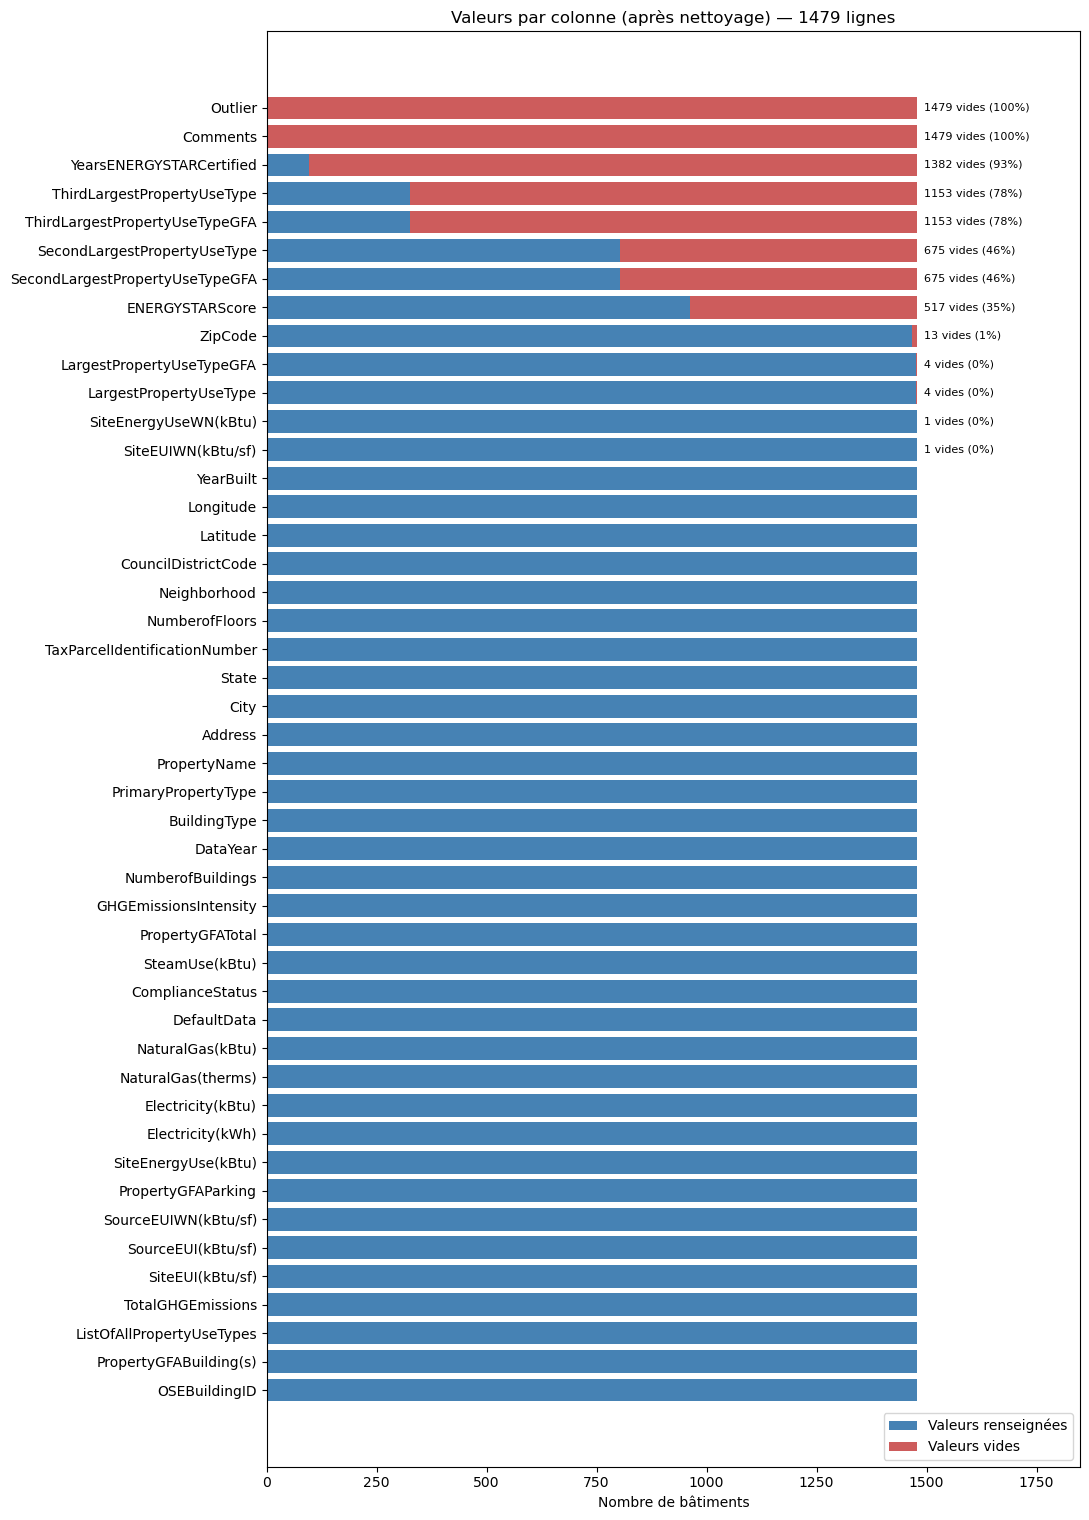

In [17]:
#Nombre de valeurs par colonne et valeurs vides APRÈS nettoyage
plot_valeurs_par_colonne(df, "Valeurs par colonne (après nettoyage)")  # même graphique qu'au début, pour comparer avant/après

Après filtrage, les colonnes cibles et les colonnes structurelles utiles (surfaces, étages, année, localisation, type) sont **complètes**. Les colonnes encore très vides (`Comments`, `Outlier`, `YearsENERGYSTARCertified`, usages secondaire/tertiaire) sont soit inutilisables, soit des vides « structurels » (pas de 2ᵉ ou 3ᵉ usage).

#### 4. Colonnes conservées / supprimées
| Groupe | Colonnes | Décision |
|---|---|---|
| Identifiants / texte libre | `OSEBuildingID`, `PropertyName`, `Address`, `TaxParcelIdentificationNumber`, `City`, `State`, `DataYear`, `Comments` | Supprimées (non informatives ou constantes) |
| Qualité du relevé | `ComplianceStatus`, `Outlier`, `DefaultData` | Servent au filtrage puis supprimées |
| Structure | `YearBuilt`, `NumberofFloors`, `NumberofBuildings`, `PropertyGFA*`, usages & surfaces des usages | **Conservées** |
| Localisation | `Neighborhood`, `Latitude`, `Longitude`, `CouncilDistrictCode`, `ZipCode` | Conservées (`Neighborhood`, lat/long) |
| Type | `BuildingType`, `PrimaryPropertyType`, `LargestPropertyUseType` | Conservées |
| Consommation / émissions | `SiteEUI*`, `SourceEUI*`, `SiteEnergyUseWN`, `Electricity*`, `NaturalGas*`, `SteamUse`, `GHGEmissionsIntensity`, `ENERGYSTARScore` | **Supprimées des features** (leakage) — seules les deux cibles sont gardées |

#### 5. Statistiques descriptives et visualisations des cibles

In [18]:
cibles = {"SiteEnergyUse(kBtu)": "Consommation d'énergie (kBtu)", "TotalGHGEmissions": "Émissions de CO2 (tonnes éq. CO2)"}
df[list(cibles)].describe().round(1).T  #statistiques des deux cibles (moyenne, médiane, etc)

,count,mean,std,min,25%,50%,75%,max
SiteEnergyUse(kBtu),1479.0,8178550.1,22539018.3,57133.2,1222024.7,2661488.0,7223922.5,448385312.0
TotalGHGEmissions,1479.0,183.6,740.0,0.4,20.2,49.2,142.9,16871.0


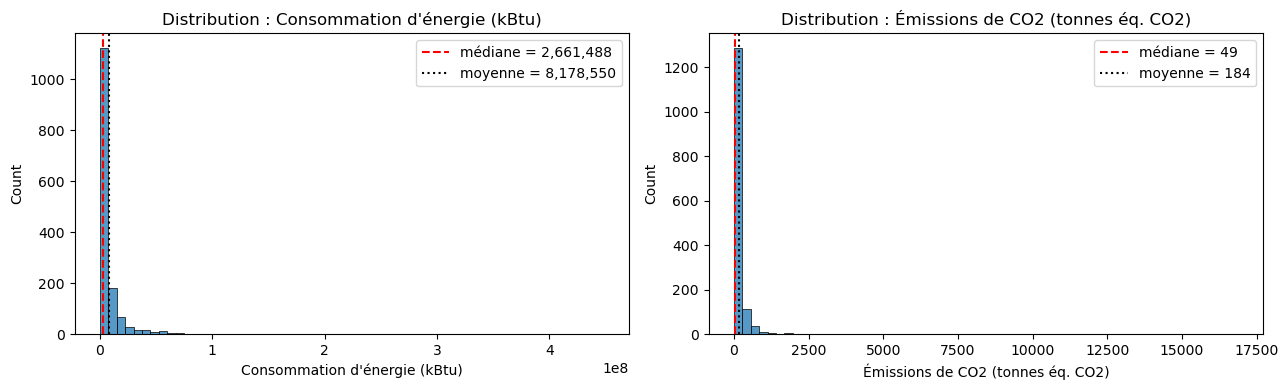

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, (col, lib) in zip(ax, cibles.items()):
    sns.histplot(df[col], bins=60, ax=a)  # histogramme : combien de bâtiments par tranche de valeur
    a.axvline(df[col].median(), color="red", ls="--", label=f"médiane = {df[col].median():,.0f}") 
    a.axvline(df[col].mean(), color="black", ls=":", label=f"moyenne = {df[col].mean():,.0f}")
    a.set_title(f"Distribution : {lib}"); a.set_xlabel(lib); a.legend()
plt.tight_layout(); 
plt.show()

**Interprétation des statistiques descriptives des cibles**
- **Énergie** : médiane ≈ 2,7 M kBtu mais moyenne ≈ 8,2 M kBtu (3 fois la médiane) ; écart-type (≈ 22,5 M) très supérieur à la moyenne ; maximum à 448 M kBtu.
- **CO2** : médiane ≈ 49 tonnes, moyenne ≈ 184 t, maximum ≈ 16 900 t.
- Dans les deux cas, la distribution est **fortement asymétrique à droite** : une grande majorité de bâtiments « modestes » et une poignée de très gros émetteurs/consommateurs (hôpitaux, grands bureaux, laboratoires) qui tirent la moyenne vers le haut. La **médiane** est donc plus représentative que la moyenne.

Conséquences pour la suite :
- seuils d'outliers basés sur des **quantiles** plutôt que sur l'IQR car elle va qualifier une part massive de grands bâtiments légitimes (hôpitaux, grands bureaux) comme des outliers, alors qu'il s'agit de profils réels et importants pour le modèle.
Utilisation des quantiles pour décider précisément de la proportion de données extrêmes à écarter (fixer un seuil à 99% et retirer les 1% de valeurs les plus extrêmes) 
- lecture des métriques en tenant compte du fait que les erreurs absolues sont dominées par les gros bâtiments.

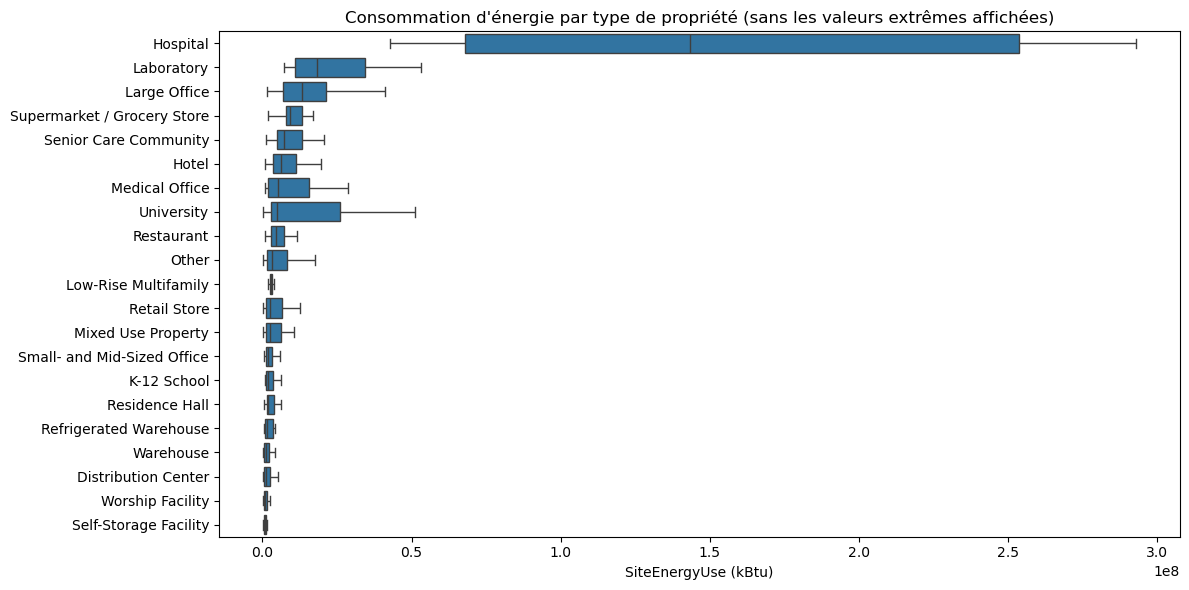

In [20]:
# Quanti vs quali : consommation par type de propriété
ordre = df.groupby("PrimaryPropertyType")["SiteEnergyUse(kBtu)"].median().sort_values(ascending=False).index  # classe les types de propriété du plus au moins consommateur (médiane)
plt.figure(figsize=(12, 6))  # crée une figure de 12 x 6 pouces
sns.boxplot(data=df, y="PrimaryPropertyType", x="SiteEnergyUse(kBtu)", order=ordre, showfliers=False)  # boîtes à moustaches : une variable qualitative contre une quantitative (sans afficher les points extrêmes)
plt.title("Consommation d'énergie par type de propriété (sans les valeurs extrêmes affichées)")  # titre du graphique
plt.xlabel("SiteEnergyUse (kBtu)"); plt.ylabel("")  # légende de l'axe horizontal, pas de légende verticale
plt.tight_layout(); plt.show()  # ajuste les marges puis affiche

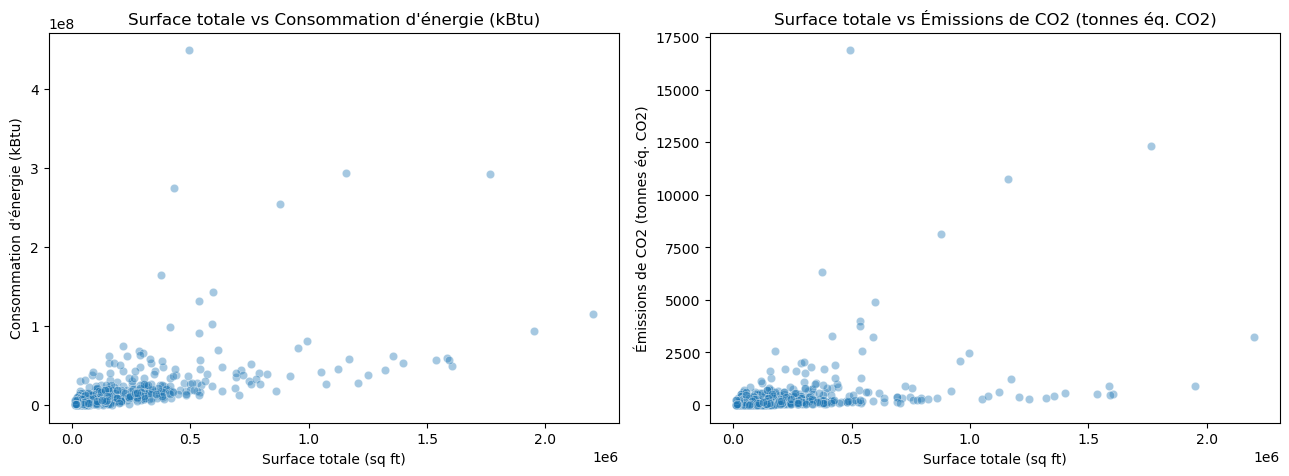

In [21]:
# Quanti vs quanti : surface vs consommation et émissions
fig, ax = plt.subplots(1, 2, figsize=(13, 5)) 
for a, (col, lib) in zip(ax, cibles.items()): 
    sns.scatterplot(data=df, x="PropertyGFATotal", y=col, alpha=0.4, ax=a)  # nuage de points : surface (x) contre cible (y), transparence pour voir les superpositions
    a.set_title(f"Surface totale vs {lib}"); a.set_xlabel("Surface totale (sq ft)"); a.set_ylabel(lib)  # titre et légendes des axes
plt.tight_layout(); plt.show()  

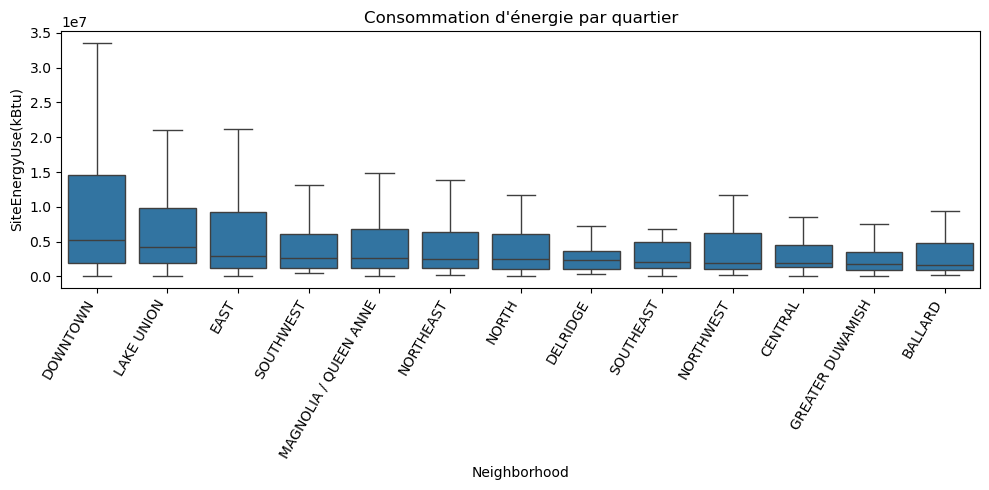

In [22]:
# Quali vs quanti : par quartier
ordre = df.groupby("Neighborhood")["SiteEnergyUse(kBtu)"].median().sort_values(ascending=False).index  # classe les quartiers par consommation médiane décroissante
plt.figure(figsize=(10, 5))  # crée une figure de 10 x 5 pouces
sns.boxplot(data=df, x="Neighborhood", y="SiteEnergyUse(kBtu)", order=ordre, showfliers=False)  #consommation par quartier
plt.xticks(rotation=60, ha="right")
plt.title("Consommation d'énergie par quartier")  # titre du graphique
plt.tight_layout(); plt.show()

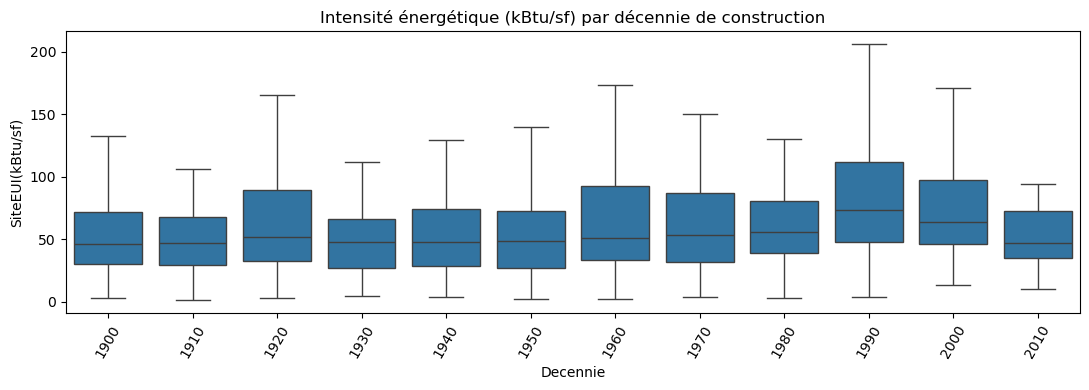

In [23]:
#temporalité : consommation par unité de surface selon la décennie de construction
df["Decennie"] = (df["YearBuilt"] // 10 * 10).astype(int)  # arrondit l'année à la décennie (1987 -> 1980) pour regrouper les bâtiments
plt.figure(figsize=(11, 4))
sns.boxplot(data=df, x="Decennie", y="SiteEUI(kBtu/sf)", showfliers=False)  # intensité énergétique (kBtu par pied carré) selon la décennie de construction
plt.xticks(rotation=60)
plt.title("Intensité énergétique (kBtu/sf) par décennie de construction")
plt.tight_layout(); plt.show() 
df = df.drop(columns="Decennie")

- Périmètre : de **3 376** relevés, il reste **1 479** bâtiments non résidentiels exploitables après nettoyage (voir le suivi des lignes).
- La **surface** est le premier moteur de la consommation et des émissions : plus un bâtiment est grand, plus il consomme et émet.
- Le **type d'usage** change fortement la consommation : un hôpital médian consomme ~58 M kBtu et émet ~1 800 t de CO2 contre ~1,3 M kBtu et ~25 t pour un entrepôt (valeurs médianes du jeu de modélisation).
- L'**âge** du bâtiment n'a pas de lien net avec l'intensité énergétique (pas d'effet monotone par décennie) : la date de construction seule est peu informative.
- Les valeurs vides sont soit **sans objet** (`Comments`, `Outlier`), soit **structurelles** (pas de 2ᵉ/3ᵉ usage), soit **liées à la consommation** (`ENERGYSTARScore`) : on ne supprime donc pas toutes les lignes incomplètes.

# Modélisation

### Import des modules

In [24]:
# Selection
from sklearn.model_selection import (  # outils de sklearn pour séparer et valider les données
    train_test_split,  # sépare les données en jeu d'entraînement et jeu de test
    GridSearchCV,  # cherche automatiquement les meilleurs hyperparamètres
    cross_validate,  # validation croisée : évalue un modèle sur plusieurs découpages
    KFold,  # définit comment découper les données pour la validation croisée
)
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error  # métriques d'évaluation : erreur quadratique, R², erreur absolue moyenne
from sklearn.inspection import permutation_importance  # mesure l'importance des variables en les mélangeant une à une

# Preprocess
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor  # appliquer des traitements différents par colonne ; transformer la cible (log) pendant l'apprentissage
from sklearn.pipeline import Pipeline  # enchaîner des étapes (préparation puis modèle) en un seul objet
from sklearn.impute import SimpleImputer  # remplacer les valeurs vides par une valeur (ici la médiane)
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, FunctionTransformer  # encodage des catégories, mise à l'échelle, application d'une fonction (log)

# Modèles
from sklearn.dummy import DummyRegressor  # modèle « bête » qui prédit toujours la même valeur : sert de référence
from sklearn.linear_model import LinearRegression  # régression linéaire : modèle simple et interprétable
from sklearn.svm import SVR  # machine à vecteurs de support pour la régression : modèle non linéaire à noyau
from sklearn.ensemble import RandomForestRegressor  # forêt aléatoire : ensemble d'arbres de décision, modèle non linéaire

### Feature Engineering

Nouvelles features construites **uniquement à partir d'informations structurelles** (aucune valeur de consommation ou d'émission → pas de data leakage) :
- **Temporalité** : âge du bâtiment, tranche d'époque de construction.
- **Structure** : surface moyenne par étage, par bâtiment, part de parking, présence de parking.
- **Usages** : nombre d'usages, parts de surface des usages principal/secondaire/tertiaire, indicateur « multi-usage ».
- **Localisation** : distance au centre-ville (Downtown), quartier.
- **Haute cardinalité** : `LargestPropertyUseType` (56 modalités) regroupé en 12 catégories + « Other ».

In [25]:
data = df.copy()  #copie de travail : on enrichit `data` sans toucher à `df`

#Temporalité
data["Age_batiments"] = 2016 - data["YearBuilt"]  #âge du bâtiment au moment du relevé (plus parlant que l'année)
data["Tranche_age_batiment"] = pd.cut(data["YearBuilt"], bins=[1800, 1920, 1945, 1970, 1990, 2005, 2016],
                          labels=["<1920", "1920-45", "1945-70", "1970-90", "1990-2005", "2005+"]).astype(str)  #nom de chaque tranche, converti en texte

#Structure
data["NumberofBuildings"] = data["NumberofBuildings"].fillna(1)  #un nombre de bâtiments vide est supposé égal à 1
data["GFAPerFloor"] = data["PropertyGFATotal"] / data["NumberofFloors"]  #surface moyenne par étage : emprise au sol du bâtiment
data["GFAPerBuilding"] = data["PropertyGFATotal"] / data["NumberofBuildings"]  #surface moyenne par bâtiment (utile pour les campus)
data["ParkingRatio"] = data["PropertyGFAParking"] / data["PropertyGFATotal"]  #part de la surface occupée par le parking
data["HasParking"] = (data["PropertyGFAParking"] > 0).astype(int)  #1 si le bâtiment a un parking, sinon 0

#Usages
for c in ["SecondLargestPropertyUseTypeGFA", "ThirdLargestPropertyUseTypeGFA"]:  #pour les surfaces du 2e et 3e usage
    data[c] = data[c].fillna(0)  #un vide signifie « pas de 2e/3e usage » donc surface 0
data["NumUseTypes"] = (data["LargestPropertyUseType"].notna().astype(int)  #compte 1 si un usage principal existe
                       + data["SecondLargestPropertyUseType"].notna().astype(int)  #+ 1 si un 2e usage existe
                       + data["ThirdLargestPropertyUseType"].notna().astype(int))  #+ 1 si un 3e usage existe : donne le nombre d'usages du bâtiment
data["IsMultiUse"] = (data["NumUseTypes"] > 1).astype(int)  #1 si le bâtiment a plusieurs usages

# Regroupement de la haute cardinalité
data["LargestPropertyUseType"] = data["LargestPropertyUseType"].fillna("Unknown")  #les usages vides deviennent « Unknown » plutôt que d'être perdus
#top_usages = data["LargestPropertyUseType"].value_counts().head(12).index  #les 12 usages principaux les plus fréquents
#data["LargestUseGroup"] = np.where(data["LargestPropertyUseType"].isin(top_usages),  #si l'usage fait partie des 12 plus fréquents...
 #                                  data["LargestPropertyUseType"], "Other")  #on le garde, sinon on le range dans « Other » (évite trop de colonnes après encodage)

def haversine_km(lat1, lon1, lat2, lon2):  #fonction qui calcule une distance en km entre deux points GPS
    """Distance à vol d'oiseau en km."""
    r = 6371  # rayon de la Terre en km
    p1, p2 = np.radians(lat1), np.radians(lat2)  #convertit les latitudes de degrés en radians (unité attendue par sin/cos)
    dphi = p2 - p1  #écart de latitude
    dl = np.radians(lon2 - lon1)  #écart de longitude converti en radians
    a = np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2  #formule de haversine : tient compte de la courbure de la Terre
    return 2 * r * np.arcsin(np.sqrt(a))  #convertit en distance en km
    
#Localisation (centre-ville de Seattle ~ 47.6062, -122.3321)
data["DistDowntownKm"] = haversine_km(data["Latitude"], data["Longitude"], 47.6062, -122.3321)  # distance de chaque bâtiment au centre-ville

#l'électricité est présente dans quasiment tous les bâtiments -> feature non discriminante, non créée.

data[["Age_batiments", "Tranche_age_batiment", "GFAPerFloor", "ParkingRatio", "NumUseTypes",  # aperçu des nouvelles variables créées
      "DistDowntownKm"]].head()  #on regarde les 5 premières lignes

,Age_batiments,Tranche_age_batiment,GFAPerFloor,ParkingRatio,NumUseTypes,DistDowntownKm
0,89,1920-45,7369.500000,0.000000,1,0.800050
1,20,1990-2005,9415.090909,0.145453,3,0.787077
2,47,1945-70,23319.756098,0.205748,1,0.970109
3,90,1920-45,6132.000000,0.000000,1,0.944139
4,36,1970-90,9754.444444,0.353115,3,1.048092


In [26]:
#Contrôle de la qualité des features créées : lien (corrélation de rang de Spearman) avec les deux cibles
nouvelles = ["Age_batiments", "GFAPerFloor", "GFAPerBuilding", "ParkingRatio", "HasParking", "NumUseTypes",  # liste des variables créées à contrôler
             "IsMultiUse", "DistDowntownKm"]  # (suite de la liste)
qualite = data[nouvelles + list(cibles)].corr(method="spearman").loc[nouvelles, list(cibles)]  # corrélation de Spearman (robuste aux valeurs extrêmes) entre chaque feature et chaque cible
qualite.sort_values("SiteEnergyUse(kBtu)", key=abs, ascending=False).round(2)  # classe du plus au moins corrélé à l'énergie (en valeur absolue)

,SiteEnergyUse(kBtu),TotalGHGEmissions
GFAPerBuilding,0.70,0.53
GFAPerFloor,0.35,0.30
HasParking,0.33,0.18
ParkingRatio,0.33,0.18
Age_batiments,-0.27,-0.16
DistDowntownKm,-0.27,-0.19
NumUseTypes,0.24,0.15
IsMultiUse,0.22,0.13


Les features créées présentent des liens cohérents avec les cibles (surface par bâtiment et par étage, présence de gaz/vapeur, nombre d'usages, distance au centre), ce qui confirme leur intérêt. Aucune n'est calculée à partir des cibles.

### Préparation des features pour la modélisation

#### Suppression des colonnes peu pertinentes / sources de leakage

In [27]:
targets = list(cibles)   # ["SiteEnergyUse(kBtu)", "TotalGHGEmissions"]
num_features = ["Age_batiments", "NumberofFloors", "NumberofBuildings", "PropertyGFATotal",  # liste des variables numériques candidates
                "PropertyGFAParking", "PropertyGFABuilding(s)", "GFAPerFloor", "GFAPerBuilding", "ParkingRatio",  # surfaces, étages, parking
                "HasParking", "NumUseTypes",  # usages
                "IsMultiUse", "LargestPropertyUseTypeGFA", "Latitude", "Longitude", "DistDowntownKm"] 
cat_features = ["BuildingType", "PrimaryPropertyType", "Neighborhood", "Tranche_age_batiment"]  # variables catégorielles (du texte) à encoder plus tard

model_df = data[num_features + cat_features + targets].copy()  # tableau final : uniquement features retenues + cibles (tout le reste, dont colonnes de fuite, est exclu)
print(model_df.shape)  # dimensions du tableau de modélisation
print(model_df.isna().sum()[model_df.isna().sum() > 0])  # colonnes qui contiennent encore des vides (à imputer plus tard)

(1479, 22)
LargestPropertyUseTypeGFA    4
dtype: int64


#### Distribution des cibles et traitement des outliers

In [28]:
print(model_df[targets].describe().round(0).T)  # statistiques des deux cibles avant retrait des extrêmes
print(model_df[targets].quantile([.01, .05, .5, .95, .99]).round(0).T)  # quantiles 1 %, 5 %, 50 %, 95 %, 99 % pour choisir les seuils d'outliers

                      count       mean         std      min        25%  \
SiteEnergyUse(kBtu)  1479.0  8178550.0  22539018.0  57133.0  1222025.0   
TotalGHGEmissions    1479.0      184.0       740.0      0.0       20.0   

                           50%        75%          max  
SiteEnergyUse(kBtu)  2661488.0  7223922.0  448385312.0  
TotalGHGEmissions         49.0      143.0      16871.0  
                         0.01      0.05       0.50        0.95        0.99
SiteEnergyUse(kBtu)  174545.0  439015.0  2661488.0  30042991.0  73134134.0
TotalGHGEmissions         1.0       4.0       49.0       567.0      2063.0


La méthode IQR supprimerait un grand nombre de gros bâtiments (distributions très asymétriques). On utilise donc des **seuils par quantiles** (1 % et 99 %) pour ne retirer que les valeurs réellement extrêmes. Pour que les deux modèles soient comparables, on ne garde que les bâtiments **non extrêmes sur les deux cibles** (mêmes lignes pour les deux modélisations).

SiteEnergyUse(kBtu) : seuils [174,545.2 ; 73,134,134.1]
TotalGHGEmissions : seuils [1.5 ; 2,063.2]

Retrait des outliers : 1479 -> 1444 (-35)


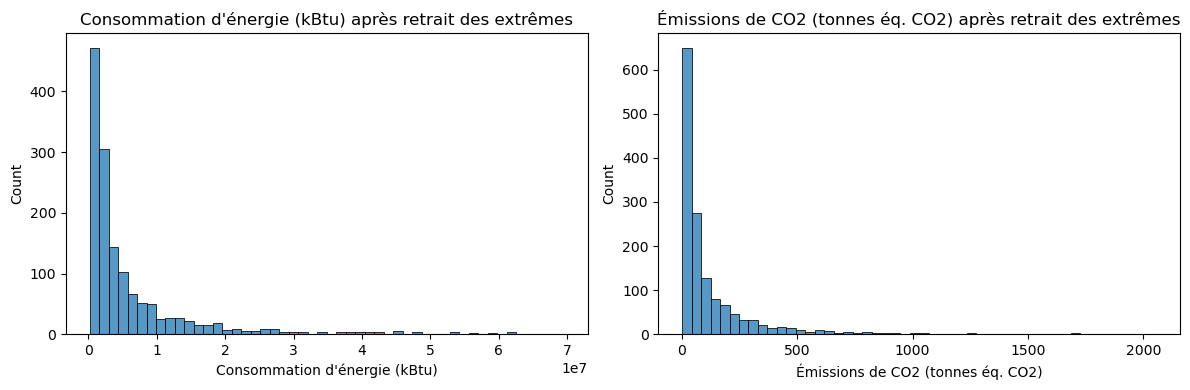

In [29]:
masque = pd.Series(True, index=model_df.index)  # masque de départ : toutes les lignes sont gardées
seuils = {}  # dictionnaire qui mémorisera les seuils de chaque cible
for t in targets:  # pour chacune des deux cibles
    q_low, q_high = model_df[t].quantile([0.01, 0.99])  # seuils bas et haut : quantiles 1 % et 99 %
    seuils[t] = (q_low, q_high)  # on mémorise ces seuils
    masque &= model_df[t].between(q_low, q_high)  # on ne garde que les lignes comprises entre les seuils, pour les deux cibles à la fois
    print(f"{t} : seuils [{q_low:,.1f} ; {q_high:,.1f}]")  # affiche les seuils retenus
avant = len(model_df)  # nombre de lignes avant retrait des extrêmes
model_df = model_df[masque].copy()  # applique le filtre sur les extrêmes
print(f"\nRetrait des outliers : {avant} -> {len(model_df)} (-{avant - len(model_df)})")  # trace avant/après

fig, ax = plt.subplots(1, 2, figsize=(12, 4))  # 2 graphiques côte à côte
for a, (col, lib) in zip(ax, cibles.items()):  # un graphique par cible
    sns.histplot(model_df[col], bins=50, ax=a); a.set_title(f"{lib} après retrait des extrêmes"); a.set_xlabel(lib)  # histogramme après filtre, avec titre et légende
plt.tight_layout(); plt.show()  # ajuste les marges puis affiche

#### Features redondantes : matrice de corrélation

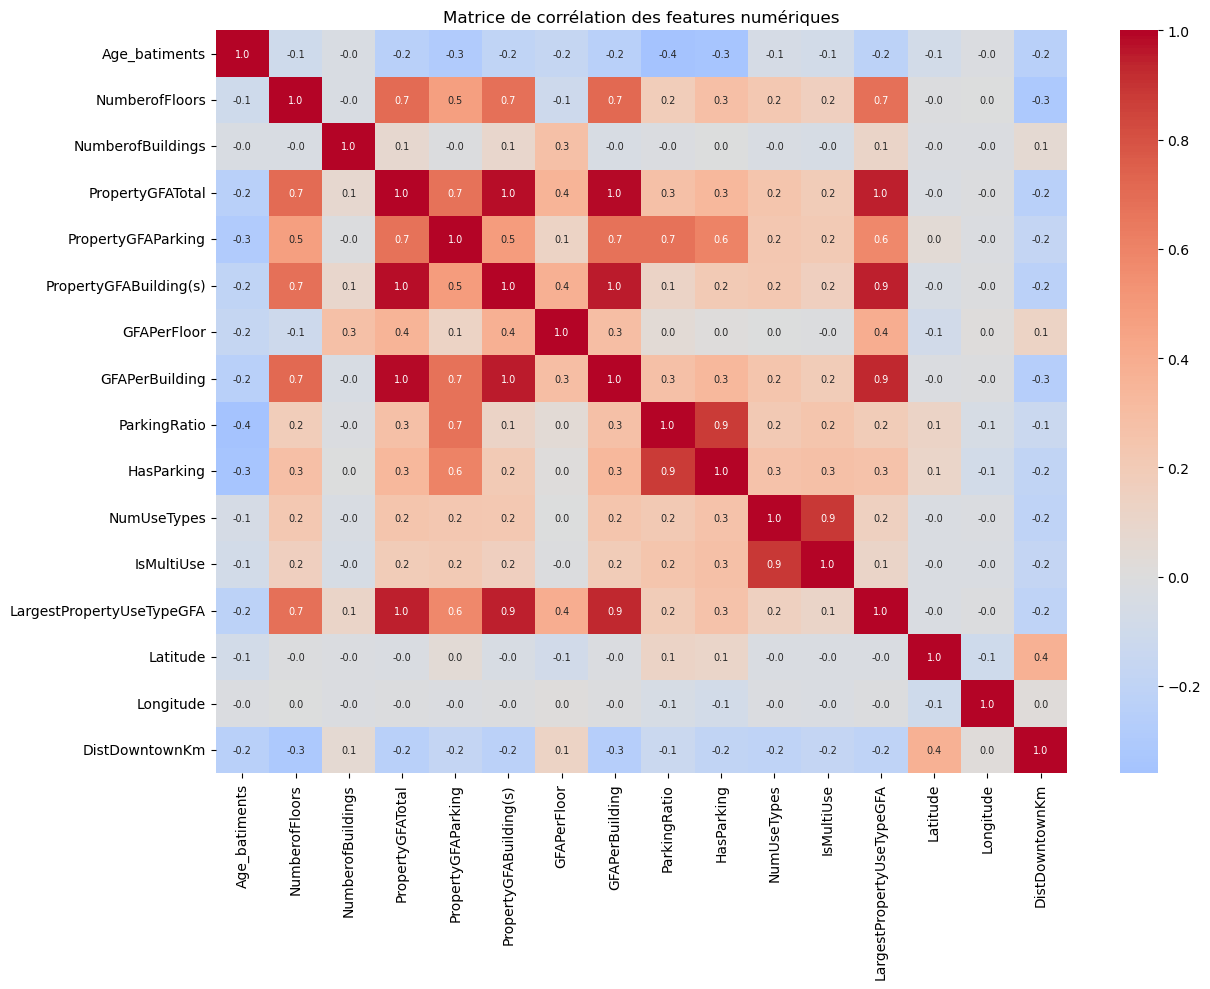

Paires |corr| > 0.7 : [('NumberofFloors', 'PropertyGFATotal', np.float64(0.7)), ('NumberofFloors', 'GFAPerBuilding', np.float64(0.72)), ('PropertyGFATotal', 'PropertyGFABuilding(s)', np.float64(0.97)), ('PropertyGFATotal', 'GFAPerBuilding', np.float64(0.99)), ('PropertyGFATotal', 'LargestPropertyUseTypeGFA', np.float64(0.95)), ('PropertyGFABuilding(s)', 'GFAPerBuilding', np.float64(0.96)), ('PropertyGFABuilding(s)', 'LargestPropertyUseTypeGFA', np.float64(0.94)), ('GFAPerBuilding', 'LargestPropertyUseTypeGFA', np.float64(0.93)), ('ParkingRatio', 'HasParking', np.float64(0.87)), ('NumUseTypes', 'IsMultiUse', np.float64(0.89))]


In [30]:
corr = model_df[num_features].corr()  #matrice de corrélation entre toutes les features numériques (valable seulement pour du numérique)
plt.figure(figsize=(13, 10))  # crée une grande figure
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".1f", annot_kws={"size": 7})  # carte de chaleur : rouge = corrélation positive, bleu = négative
plt.title("Matrice de corrélation des features numériques")
plt.tight_layout(); plt.show()

paires = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(corr.columns) for b in corr.columns[i + 1:]  # liste toutes les paires de features (sans doublon)...
          if abs(corr.loc[a, b]) > 0.7]  # ...dont la corrélation dépasse 0,9 : elles apportent la même information
print("Paires |corr| > 0.7 :", paires)  # affiche les paires redondantes

In [31]:
#On retire un membre de chaque paire redondante (on garde la plus interprétable)
redondantes = ["PropertyGFABuilding(s)", "LargestPropertyUseTypeGFA", "IsMultiUse", "HasParking", "GFAPerBuilding"]  # features redondantes choisies d'après les paires ci-dessus
redondantes = [c for c in redondantes if c in num_features]  # sécurité : on ne garde que celles qui existent encore dans la liste
num_features = [c for c in num_features if c not in redondantes]  # retire ces features de la liste des features numériques
model_df = model_df.drop(columns=redondantes)  # retire aussi ces colonnes du tableau
print("Retirées :", redondantes)  # affiche ce qui a été retiré
print("Features numériques restantes :", num_features)  # affiche la liste finale des features numériques

Retirées : ['PropertyGFABuilding(s)', 'LargestPropertyUseTypeGFA', 'IsMultiUse', 'HasParking', 'GFAPerBuilding']
Features numériques restantes : ['Age_batiments', 'NumberofFloors', 'NumberofBuildings', 'PropertyGFATotal', 'PropertyGFAParking', 'GFAPerFloor', 'ParkingRatio', 'NumUseTypes', 'Latitude', 'Longitude', 'DistDowntownKm']


#### Lien features / cibles

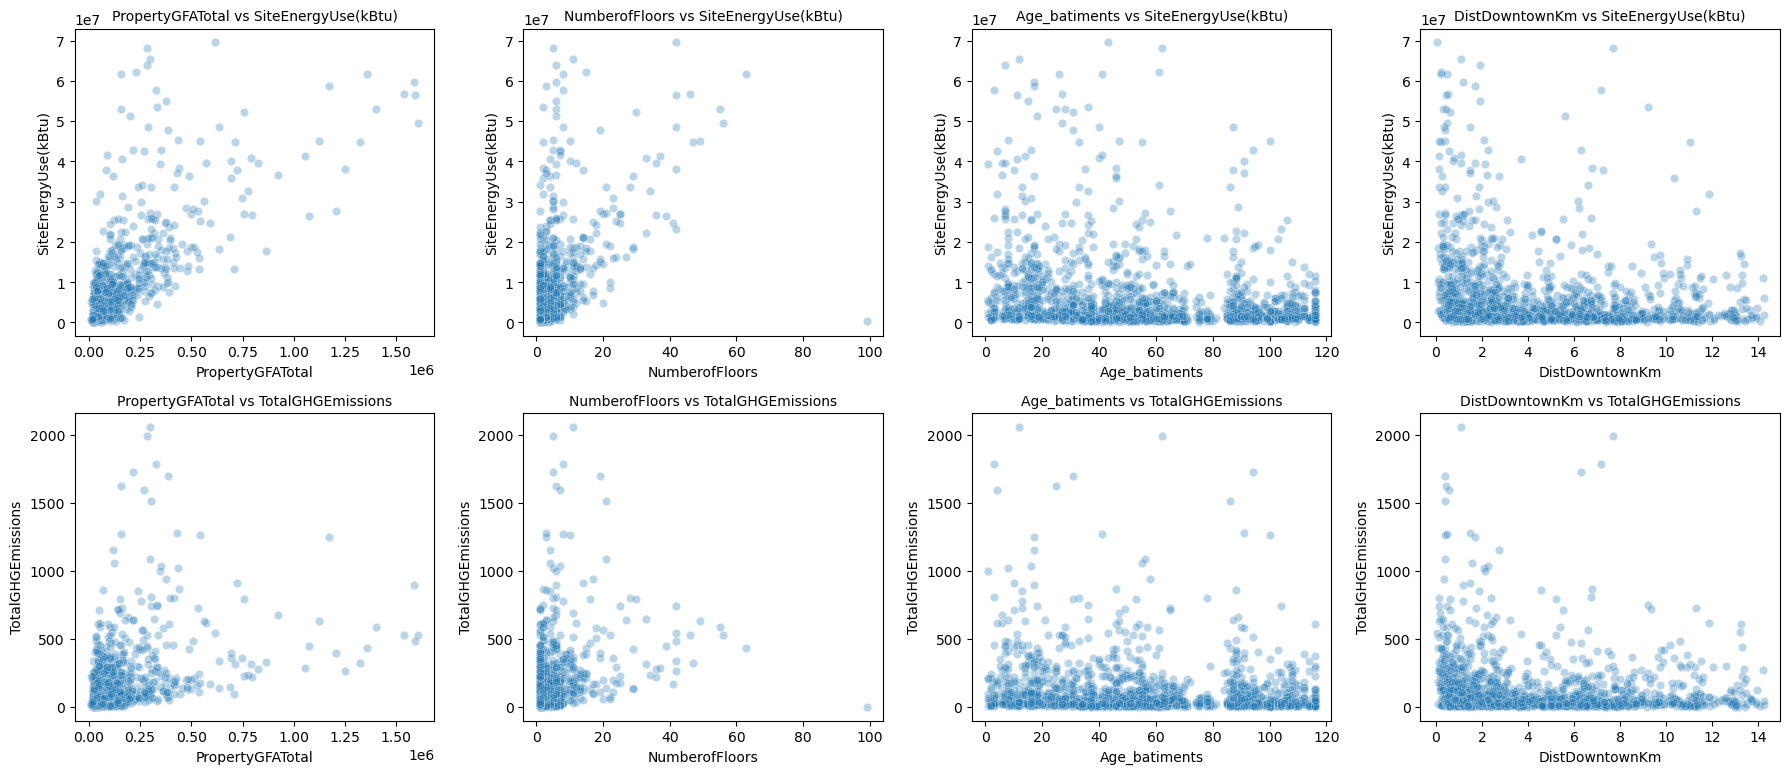

In [32]:
fig, ax = plt.subplots(2, 4, figsize=(18, 8))  # grille de 2 lignes (une par cible) x 4 colonnes (une par feature)
feats = ["PropertyGFATotal", "NumberofFloors", "Age_batiments", "DistDowntownKm"]  # les 4 features numériques à comparer aux cibles
for i, (col, lib) in enumerate(cibles.items()):  # i = ligne de la grille (0 = énergie, 1 = CO2)
    for a, f in zip(ax[i], feats):  # une case de la ligne pour chaque feature
        sns.scatterplot(data=model_df, x=f, y=col, alpha=0.3, ax=a)  # nuage de points feature contre cible
        a.set_title(f"{f} vs {col}", fontsize=10) 
plt.tight_layout(); plt.show() 

In [33]:
# Variable qualitative vs cibles : type de propriété principal (médiane)
med = model_df.groupby("PrimaryPropertyType")[targets].median().sort_values("SiteEnergyUse(kBtu)", ascending=False)  # médiane des deux cibles pour chaque type de propriété, du plus consommateur au moins consommateur
med.round(0)  # affiche le tableau arrondi

,SiteEnergyUse(kBtu),TotalGHGEmissions
PrimaryPropertyType,,
Hospital,57764408.0,1790.0
Large Office,13226733.0,131.0
Laboratory,12015936.0,422.0
Supermarket / Grocery Store,9290214.0,227.0
Senior Care Community,7366733.0,203.0
Hotel,5827596.0,190.0
Medical Office,4765754.0,69.0
Restaurant,4475650.0,127.0
University,4116872.0,96.0


#### Séparation X / y

In [34]:
X = model_df[num_features + cat_features]  # X : le tableau des features (ce que le modèle voit)
y = model_df[targets]          # DataFrame à deux colonnes : une cible par modèle
print(X.shape, y.shape)  # vérifie que X et y ont le même nombre de lignes

(1444, 15) (1444, 2)


#### Encodage des variables catégorielles
- `OneHotEncoder` pour les variables catégorielles (nominales, sans ordre ; `LabelEncoder` ne convient qu'à une cible ou à des variables ordinales). `max_categories=15` limite la dimension.
- **Les variables numériques sont gardées brutes** (pas de normalisation, pas de transformation) : on cherche à présenter le meilleur modèle avec le moins de modifications possible. Seules les rares valeurs vides (4 valeurs de `LargestUseShare`) sont remplacées par la médiane, car la régression linéaire et le SVR refusent les vides.
- Conséquence à connaître : le **Random Forest n'est pas sensible aux échelles** (il compare des seuils), alors que la **régression linéaire et le SVR le sont** : ces deux modèles seront désavantagés
- Le préprocesseur est placé **dans le pipeline** : tout ce qui est calculé (médianes, modalités) l'est sur le jeu d'entraînement uniquement à chaque fold (pas de fuite).

In [35]:
# Les variables numériques restent brutes : on remplit seulement les rares valeurs vides, sans log ni scaling
preprocessor = ColumnTransformer([  # applique un traitement différent selon le type de colonne
    ("num", SimpleImputer(strategy="median"), num_features),  # variables numériques : valeurs brutes, seules les valeurs vides sont remplacées par la médiane (la régression linéaire et le SVR refusent les vides)
    ("cat", OneHotEncoder(handle_unknown="ignore", max_categories=15, sparse_output=False), cat_features),])  # variables catégorielles, une colonne 0/1 par modalité (max 15, modalité inconnue ignorée au test)


### Comparaison de différents modèles supervisés

**Démarche commune à tous les modèles et aux deux cibles** :
1. Un **unique** split train/test (80/20) : mêmes lignes pour tous les modèles et les deux cibles.
2. Validation croisée sur le train (`cross_validate`) → R², MAE, RMSE sur train et validation.
3. Entraînement final sur tout le train, évaluation sur le test.
5. Trois familles de modèles testées : **linéaire** (régression linéaire), **à noyau / SVM** (SVR), **à base d'arbres** (Random Forest) et **XGBoost**

In [36]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)  # sépare 80 % entraînement / 20 % test, mêmes lignes pour tous les modèles
cv = KFold(n_splits=5, shuffle=True, random_state=42)  #validation croisée en 5 parties, mélangées, avec graine fixe
print(X_train.shape, X_test.shape)  #taille des deux jeux de données
    
def evaluer_modele(nom, estimateur, target):
    modele = Pipeline([("prep", preprocessor), ("model", estimateur)])  # préparation puis modèle
    scoring = {"r2": "r2", "mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"}  # 3 métriques
    cvres = cross_validate(modele, X_train, y_train[target], cv=cv, scoring=scoring,
                           return_train_score=True, n_jobs=-1)  # validation croisée sur le train
    modele.fit(X_train, y_train[target])  # entraînement final sur tout le train
    pred = modele.predict(X_test)  # prédictions sur le test
    return {
        "Modèle": nom,
        "R2 train (CV)": cvres["train_r2"].mean(), 
        "R2 val (CV)": cvres["test_r2"].mean(),
        "MAE val (CV)": -cvres["test_mae"].mean(), 
        "RMSE val (CV)": -cvres["test_rmse"].mean(),
        "R2 test": r2_score(y_test[target], pred),                       # vraie valeur contre prédiction
        "MAE test": mean_absolute_error(y_test[target], pred),
        "RMSE test": np.sqrt(mean_squared_error(y_test[target], pred)),
    }

(1155, 15) (289, 15)


In [37]:
modeles = {  # dictionnaire des modèles à comparer (paramètres par défaut)
    "Dummy (moyenne)": DummyRegressor(strategy="mean"),
    "Régression linéaire": LinearRegression(),
    "Random Forest": RandomForestRegressor(random_state=42),
    "SVR": SVR(),
    "XGBoost": XGBRegressor(random_state=42),
}
resultats = {}  # dictionnaire qui stockera le tableau de résultats de chaque cible
for t in targets:  # pour chaque cible (énergie puis CO2)
    resultats[t] = pd.DataFrame([evaluer_modele(nom, m, t) for nom, m in modeles.items()]).set_index("Modèle")  # évalue chaque modèle et met les résultats dans un tableau
    print(f"\nCible : {t}")
    print(resultats[t].round(3).to_string())  # affiche le tableau arrondi
    #Affichage du tableau sous forme de DataFrame interactif dans le notebook


Cible : SiteEnergyUse(kBtu)
                     R2 train (CV)  R2 val (CV)  MAE val (CV)  RMSE val (CV)  R2 test     MAE test     RMSE test
Modèle                                                                                                          
Dummy (moyenne)              0.000       -0.006   6140664.629   9.733900e+06   -0.000  6266252.500  9.994131e+06
Régression linéaire          0.638        0.592   3341807.565   6.182653e+06    0.592  3187119.744  6.382651e+06
Random Forest                0.945        0.601   3133473.715   6.075238e+06    0.630  3027661.041  6.074744e+06
SVR                         -0.143       -0.146   5113472.726   1.039108e+07   -0.126  5061953.397  1.060161e+07
XGBoost                      0.999        0.545   3352103.293   6.509102e+06    0.524  3229061.353  6.896332e+06

Cible : TotalGHGEmissions
                     R2 train (CV)  R2 val (CV)  MAE val (CV)  RMSE val (CV)  R2 test  MAE test  RMSE test
Modèle                                        

**Interprétation**
*Cible énergie (`SiteEnergyUse`)*
- **Régression linéaire** : R² val ≈ 0,59 / test ≈ 0,59, peu de sur-apprentissage (train 0,64) : simple et stable mais limité.
- **Random Forest** : meilleur en validation croisée (R² ≈ 0,60, MAE ≈ 3.13 M kBtu, RMSE ≈ 6 M) mais fort sur-apprentissage (train 0,95).
- **XGBoost** : sur-apprentissage beaucoup trop haut (train 0,99) -> biais?
- 
*Cible CO2 (`TotalGHGEmissions`)*
- Tâche **plus difficile** : R² val ≈ 0,40 pour les meilleurs modèles (SVR 0,38, Random Forest 0,40). La **régression linéaire est instable** (R² val ≈ -0,07, mais 0,33 sur le test) : elle ne capture pas la relation non linéaire entre structure et émissions.
- Les émissions dépendent fortement de la **source d'énergie** (gaz, vapeur) et du comportement des usagers, mal décrits par les seules données structurelles.

*Choix* : le **Random Forest** est retenu pour les deux cibles (meilleur R² et RMSE en validation croisée ; pour le CO2, le SVR a une MAE de validation très légèrement meilleure : 70,0 t contre 71,2 t). Les écarts entre SVR et Random Forest restent faibles : un seul split de test est bruité, on s'appuie donc surtout sur la validation croisée.

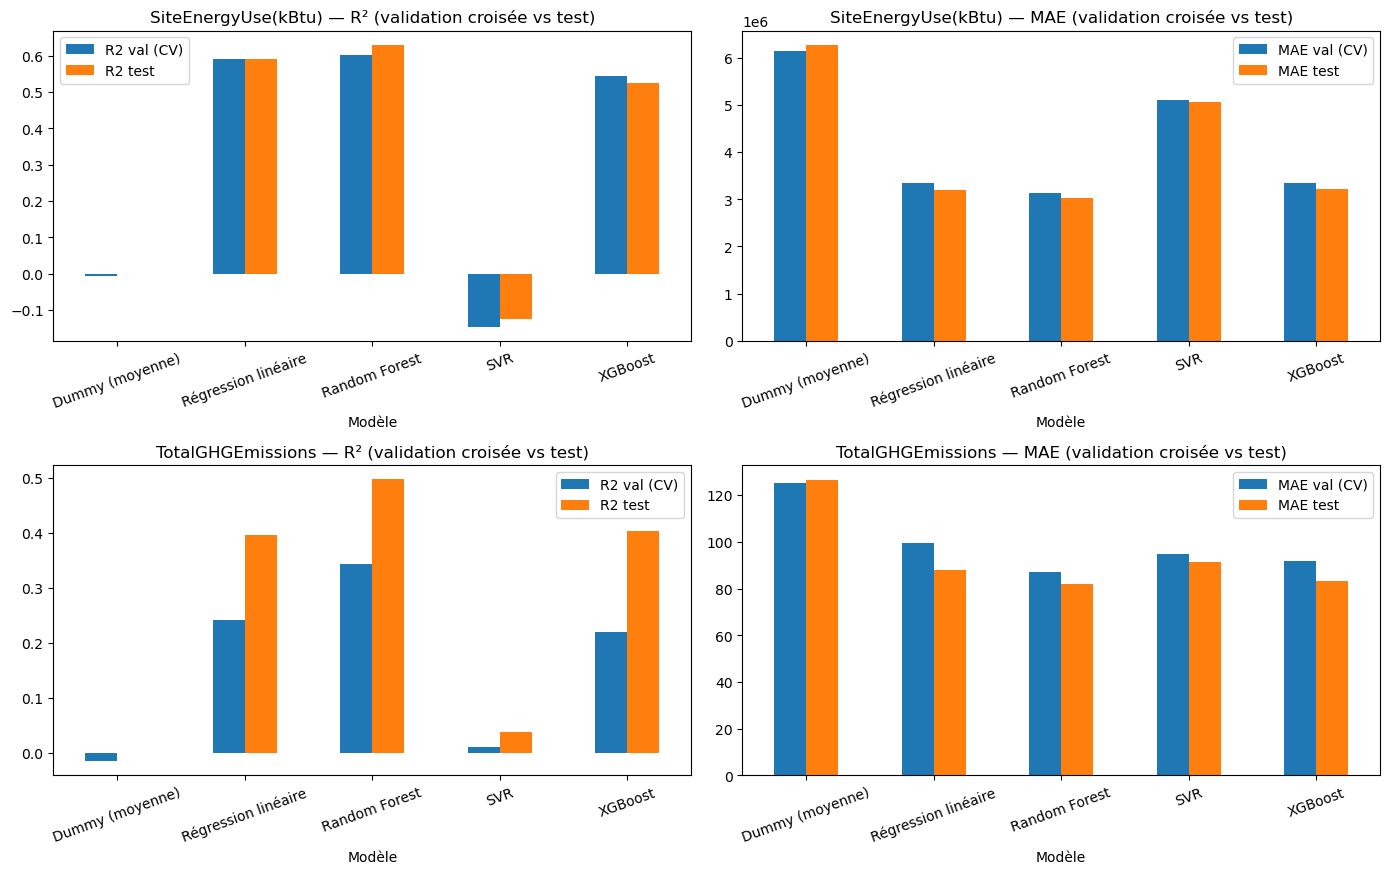

In [38]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))  # grille 2 x 2 : lignes = cibles, colonnes = R² / MAE
for i, t in enumerate(targets):  # i = ligne de la grille
    resultats[t][["R2 val (CV)", "R2 test"]].plot.bar(ax=ax[i, 0], rot=20); ax[i, 0].set_title(f"{t} — R² (validation croisée vs test)")  # barres du R² : validation croisée contre test
    resultats[t][["MAE val (CV)", "MAE test"]].plot.bar(ax=ax[i, 1], rot=20); ax[i, 1].set_title(f"{t} — MAE (validation croisée vs test)")  # barres de la MAE : validation croisée contre test
plt.tight_layout(); plt.show()  # ajuste les marges puis affiche

### Optimisation et interprétation du modèle

A réaliser :
* Reprennez le meilleur algorithme que vous avez sécurisé via l'étape précédente, et réalisez une GridSearch de petite taille sur au moins 3 hyperparamètres.
* Si le meilleur modèle fait partie de la famille des modèles à arbres (RandomForest, GradientBoosting) alors utilisez la fonctionnalité feature importance pour identifier les features les plus impactantes sur la performance du modèle. Sinon, utilisez la méthode Permutation Importance de sklearn. 